# What Do Employers in India Ask For in Data Analyst Jobs?

**The question:** if I want a data analyst job in India, which skills should I learn first, what do the jobs look like, and how much remote work is there?

**Data:** job postings from the Adzuna job search API, collected on 24 November 2026. I used two views of the same market:

1. **Skill demand.** For every skill I asked Adzuna how many India postings with "data analyst" in the title mention it anywhere in the full job text (938 postings in total). This is the best measure of what employers want.
2. **A closer look at 212 recent postings** (June to November 2026) to see roles, seniority, cities, employers, remote work and pay. Adzuna only returns the first 500 characters of each description, so I use this set for the *shape* of the market, not for counting skills.

The collection scripts are in `data_collection/` so the numbers can be refreshed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BLUE, LIGHT, SAGE, CORAL, SAND, NAVY = "#6F8FAE", "#A9BDD0", "#8FB0A2", "#D9917F", "#E0C492", "#3F566E"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#C9D3DC", "axes.labelcolor": "#44505C",
                     "xtick.color": "#44505C", "ytick.color": "#44505C", "font.size": 11,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = Path("../images"); IMG.mkdir(exist_ok=True)

demand = pd.read_csv("../data/skill_demand_counts.csv")
jobs = pd.read_csv("../data/india_data_analyst_jobs.csv")
total = int(demand.loc[demand.type == "total", "postings"].iloc[0])
print(f"Postings titled 'data analyst' on Adzuna India: {total}")
print(f"Recent postings in the detailed sample: {len(jobs)}")

Postings titled 'data analyst' on Adzuna India: 938
Recent postings in the detailed sample: 212


## 1. How I prepared the data

The detailed sample started as 424 downloaded postings and was narrowed down like this (`data_collection/build_dataset.py` does every step):

In [2]:
pd.DataFrame({
    "step": ["Postings downloaded", "Remove repeated ids", "Keep analyst-type titles", "Keep postings from June 2026 on",
             "Remove reposts (same title, company, city)"],
    "postings left": [424, 406, 370, 222, 212],
})

,step,postings left
0,Postings downloaded,424
1,Remove repeated ids,406
2,Keep analyst-type titles,370
3,Keep postings from June 2026 on,222
4,"Remove reposts (same title, company, city)",212


I dropped older postings because a job from 2019 says nothing about today's market. I also removed reposts so one employer's repeated advert is not counted several times.

**Salary** is shown on only 34 of the 212 postings, and a few ranges are not believable (for example 50,000 to 7,00,000 rupees a year). I kept only employer-stated salaries with a sensible range (top no more than 3 times the bottom), which leaves **28**. I treat the salary results as a rough guide only.

## 2. Which skills do employers ask for?

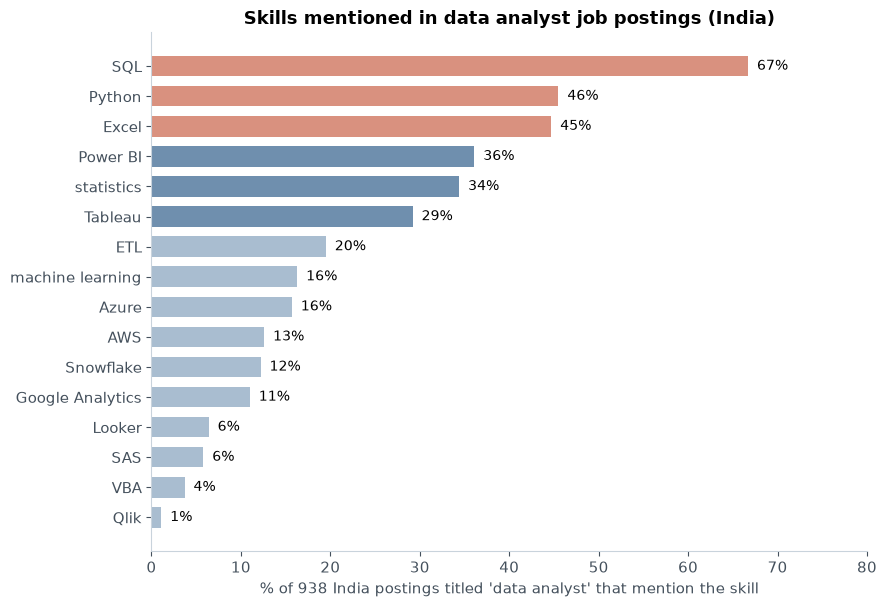

,skill,postings,share_pct
0,SQL,626,66.7
1,Python,427,45.5
2,Excel,419,44.7
3,Power BI,339,36.1
4,statistics,323,34.4
5,Tableau,274,29.2
6,ETL,183,19.5
7,machine learning,153,16.3
8,Azure,147,15.7
9,AWS,118,12.6


In [3]:
skills = demand[demand.type == "skill"].sort_values("share_pct")
fig, ax = plt.subplots(figsize=(9, 6.2))
colors = [CORAL if v >= 40 else (BLUE if v >= 20 else LIGHT) for v in skills.share_pct]
ax.barh(skills.skill, skills.share_pct, color=colors, height=0.68)
for y, v in enumerate(skills.share_pct):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=10)
ax.set_xlim(0, 80); ax.set_xlabel(f"% of {total} India postings titled 'data analyst' that mention the skill")
ax.set_title("Skills mentioned in data analyst job postings (India)")
plt.tight_layout(); plt.savefig(IMG / "skills_demand.png", dpi=150, bbox_inches="tight"); plt.show()
skills.sort_values("share_pct", ascending=False)[["skill", "postings", "share_pct"]].reset_index(drop=True)

- **SQL is the clear number one:** two out of three postings (67%) mention it.
- **Excel (45%) and Python (46%)** come next, almost level with each other.
- **Power BI (36%) is mentioned more than Tableau (29%)**, about 1.2 times as often.
- **Statistics (34%)** matters more than many beginners expect, ahead of machine learning (16%).
- Cloud and warehouse tools (Azure, AWS, Snowflake) show up in 12% to 16%, and ETL in 20%. They are a clear second tier after the core tools.
- **SAS, Qlik and VBA are rare** (1% to 6%).

### Do the 212 recent postings agree?

That sample only shows the first 500 characters, so most postings mention no tool at all. But among the postings that *do* name a tool, the ranking should look the same if the first measure is reliable.

In [4]:
tools = ["SQL", "Excel", "Power BI", "Tableau", "Python"]
named = jobs[jobs[tools].any(axis=1)]
check = pd.DataFrame({
    "skill": tools,
    "full-text count (938 postings)": [f"{demand.loc[demand.skill == t, 'share_pct'].iloc[0]:.0f}%" for t in tools],
    f"recent sample ({len(named)} postings that name a tool)": [f"{named[t].mean() * 100:.0f}%" for t in tools],
})
print(f"Postings in the sample that name at least one of these tools: {len(named)} of {len(jobs)}")
check

Postings in the sample that name at least one of these tools: 43 of 212


,skill,full-text count (938 postings),recent sample (43 postings that name a tool)
0,SQL,67%,53%
1,Excel,45%,35%
2,Power BI,36%,35%
3,Tableau,29%,16%
4,Python,46%,26%


SQL comes first and Tableau comes last in both views, and Power BI is mentioned more often than Tableau in each (by a wider margin in the sample). That agreement gives me more confidence in the full-text numbers. Python ranks lower in the small sample than in the full counts, which is expected: the first 500 characters of an advert are mostly about the company and the role, and the skills list often comes later. The exact percentages differ for the same reason, so I use the sample only as a sanity check.

## 3. What do the jobs look like?

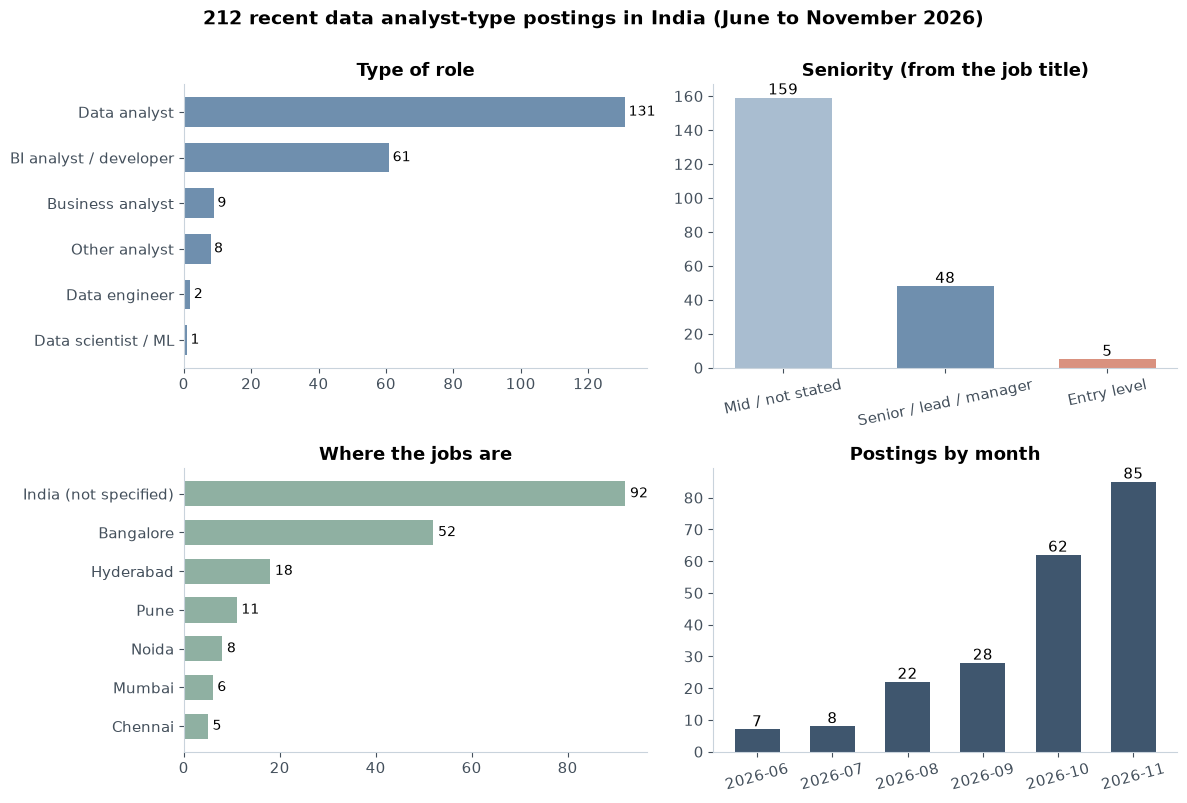

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

roles = jobs.role_group.value_counts().sort_values()
axes[0, 0].barh(roles.index, roles.values, color=BLUE, height=0.65); axes[0, 0].set_title("Type of role")
for y, v in enumerate(roles.values): axes[0, 0].text(v + 1, y, str(v), va="center", fontsize=10)

sen = jobs.seniority.value_counts()
axes[0, 1].bar(sen.index, sen.values, color=[LIGHT, BLUE, CORAL][: len(sen)], width=0.6); axes[0, 1].set_title("Seniority (from the job title)")
axes[0, 1].tick_params(axis="x", rotation=12)
for x, v in enumerate(sen.values): axes[0, 1].text(x, v + 2, str(v), ha="center")

cities = jobs.city.value_counts().head(7).sort_values()
axes[1, 0].barh(cities.index, cities.values, color=SAGE, height=0.65); axes[1, 0].set_title("Where the jobs are")
for y, v in enumerate(cities.values): axes[1, 0].text(v + 1, y, str(v), va="center", fontsize=10)

months = jobs.posted_month.value_counts().sort_index()
axes[1, 1].bar(months.index, months.values, color=NAVY, width=0.6); axes[1, 1].set_title("Postings by month")
axes[1, 1].tick_params(axis="x", rotation=15)
for x, v in enumerate(months.values): axes[1, 1].text(x, v + 1, str(v), ha="center")

fig.suptitle(f"{len(jobs)} recent data analyst-type postings in India (June to November 2026)", y=1.0, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(IMG / "market_snapshot.png", dpi=150, bbox_inches="tight"); plt.show()

- **Most roles are plain "data analyst" (131) or BI analyst/developer (61).** Business analyst titles are only 9, but Adzuna's search was for data and BI roles, so this is not a full picture of business analyst demand.
- **Bangalore leads** with 52 postings, then Hyderabad (18) and Pune (11). Another 92 postings just say "India" without a city.
- **Very few titles say "junior" or "entry level"** (5 of 212). Most titles do not state a level, so I can only say that senior titles are 23% of postings.
- **The rise towards November does not mean hiring is growing.** Older adverts expire and disappear from the site, so recent months always look fuller.

In [6]:
print("Top employers in the sample")
print(jobs.company.value_counts().head(8).to_string())
print()
exp = jobs.experience_years_min.dropna()
print(f"Experience stated in the text (first 500 characters): {len(exp)} postings, median {exp.median():.0f} years, middle half {exp.quantile(.25):.0f} to {exp.quantile(.75):.0f} years")

Top employers in the sample
company
EXL                      6
Amazon                   5
Applied Materials        4
Genl Mills India Priv    4
Diebold Nixdorf          3
Kyndryl                  2
Advanced Energy          2
Gururo                   2

Experience stated in the text (first 500 characters): 28 postings, median 4 years, middle half 2 to 6 years


## 4. Remote and work-from-home jobs

In [7]:
arr = demand[demand["type"] == "work arrangement"][["skill", "postings", "share_pct"]].rename(columns={"skill": "mentions"})
arr

,mentions,postings,share_pct
17,remote,126,13.4
18,work from home,45,4.8
19,hybrid,127,13.5


About **13.4% of data analyst postings mention "remote"**, **4.8% mention "work from home"** and **13.5% mention "hybrid"**. Some of these mean "remote-friendly" or "occasional" rather than fully remote, so the true share of fully remote jobs is lower. Remote analyst work in India exists, but it is a small slice of the market.

These are the remote or work-from-home postings in the recent sample:

In [8]:
remote = jobs[jobs.work_mode == "Remote / WFH"][["title", "company", "city", "posted_date"]].sort_values("posted_date", ascending=False)
remote.reset_index(drop=True)

,title,company,city,posted_date
0,Data Analyst / Data Engineer,Pavago,India (not specified),2026-11-19
1,Salesforce Functional Data Analyst JobID JC001...,WLEN WorldJobs LLP,India (not specified),2026-11-16
2,INTL - India - REMOTE Data Analyst/ Power BI D...,Insight Global,India (not specified),2026-10-15
3,Data Analyst Intern,Innovexis,Bangalore,2026-10-14
4,Associate - Business Analyst,EXL,Pune,2026-10-05
5,"Data Analyst (Remote, India)",Peakflo,India (not specified),2026-09-18
6,Data Analyst - Power Transformer,Hitachi,Vadodara,2026-09-17
7,Remote IT Operations Analyst Data Entry and Se...,FlexBoard,India (not specified),2026-08-25
8,arenaflex Remote Data Analyst Business Analyti...,remote click jobs,India (not specified),2026-08-18
9,Data Analyst Data Science Chennai Tamil Nadu I...,Arcadia Power Inc,Chennai,2026-08-18


Treat the remote list with care. A few of these adverts look generic or too good to be true (vague company names, "click" jobs, titles that read like keyword lists). Always check the company on its own website before applying, and never pay anything to get a job.

## 5. What do the jobs pay?

Postings with a usable stated salary: 28 of 212
Median: 7.25 lakh a year | middle half: 4.4 to 14.6 lakh | range 0.2 to 30.0



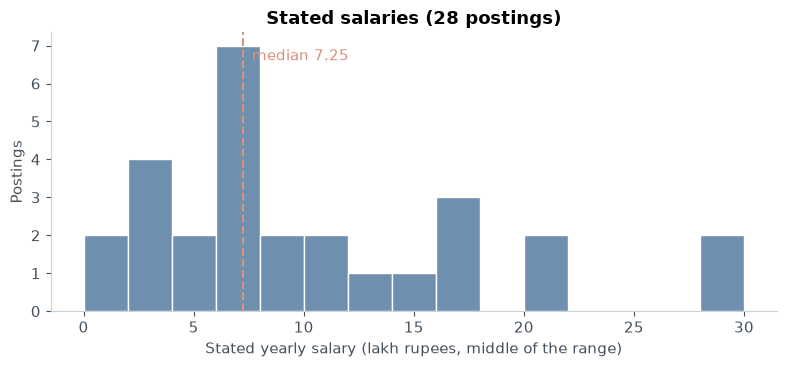

In [9]:
sal = jobs.dropna(subset=["salary_lpa"])
print(f"Postings with a usable stated salary: {len(sal)} of {len(jobs)}")
print(f"Median: {sal.salary_lpa.median():.2f} lakh a year | middle half: {sal.salary_lpa.quantile(.25):.1f} to {sal.salary_lpa.quantile(.75):.1f} lakh | range {sal.salary_lpa.min():.1f} to {sal.salary_lpa.max():.1f}")
print()
by = sal.groupby("seniority").salary_lpa.agg(postings="count", median_lakh="median").round(2)
by

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(sal.salary_lpa, bins=np.arange(0, 32, 2), color=BLUE, edgecolor="white")
ax.axvline(sal.salary_lpa.median(), color=CORAL, ls="--", lw=1.5)
ax.text(sal.salary_lpa.median() + 0.4, ax.get_ylim()[1] * 0.9, f"median {sal.salary_lpa.median():.2f}", color=CORAL)
ax.set_xlabel("Stated yearly salary (lakh rupees, middle of the range)"); ax.set_ylabel("Postings")
ax.set_title(f"Stated salaries ({len(sal)} postings)")
plt.tight_layout(); plt.savefig(IMG / "salary_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

The median stated salary is about **7 lakh a year** (7.25), and the middle half of postings sit between roughly 4 and 15 lakh. Senior titles are paid much more than the rest (the senior group has only 4 postings, so this is a hint, not a result). **28 postings is a small sample**, and employers who state a salary may not be typical. I would not quote these numbers as "the market rate".

## What this means for someone starting out

1. **Learn SQL first.** It is in two thirds of postings.
2. **Be solid in Excel and learn basic Python** (pandas). Each appears in about 45% of postings.
3. **Pick Power BI as your first dashboard tool.** It appears more often than Tableau, and it is free to start with.
4. **Do not skip statistics.** More than a third of postings mention it.
5. **Add a cloud or ETL skill later** (Azure, Snowflake or basic pipelines). They appear in roughly 1 in 8 to 1 in 5 postings.
6. **For remote work, expect a small slice of the market** and check every employer carefully.

## Limits of this analysis

- It is a **snapshot from one job site on one day** (Adzuna, 24 November 2026). Other sites such as LinkedIn or Naukri may look different, and I could not use them.
- Skill counts come from keyword matching on the job text, so "SQL" in the text means the job mentions SQL, not that it is a hard requirement.
- The 938 count includes any currently listed advert on Adzuna, so a few old or repeated adverts may be in it.
- The detailed sample (212 postings) is small. Salaries (28) and experience (28) are smaller still.
- Adzuna has no Saudi Arabia or Gulf listings, so this study is about India only.